# 02 — Model evaluation and threshold tradeoffs

This notebook reads the frozen baseline artifacts. It never fits models, selects
thresholds or changes the holdout. Run `python -m credit_risk.train` from a clean
checkout before viewing this if the baseline artifacts are absent. The README
explains how to reproduce into a separate directory.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RUN = ROOT / 'artifacts/baseline'
decision = json.loads((RUN / 'decision.json').read_text(encoding='utf-8'))
display(pd.read_csv(RUN / 'training_cv.csv'))
display(pd.Series({k: decision[k] for k in ['selected_family', 'selected_model', 'threshold', 'selection_rule']}))

,family,configuration,parameters,mean_ap,std_ap,mean_roc_auc,fold_ap
0,logistic,unweighted,{'balanced': False},0.545504,0.009542,0.766731,"[0.5426506267309756, 0.5355081117281835, 0.558..."
1,logistic,balanced,{'balanced': True},0.543488,0.010101,0.767084,"[0.5426426210077095, 0.5315603889461593, 0.556..."
2,forest,depth6,{'depth': 6},0.546094,0.008411,0.775939,"[0.5479468243303325, 0.5349915534117411, 0.555..."
3,forest,depth12,{'depth': 12},0.552906,0.005390,0.783530,"[0.5528276168475973, 0.5463451751813828, 0.559..."


selected_family                                               forest
selected_model                                                forest
threshold                                                   0.307695
selection_rule     Family/configuration: max training-CV AP; cali...
dtype: object

## Validation decisions
CV selected the family on training folds. Validation then compared raw and sigmoid
Brier scores for that family. Calibration was fitted using training-only out-of-fold
predictions. No test score participates in these choices.

In [2]:
display(pd.read_csv(RUN / 'validation_metrics.csv'))
display(pd.Series(decision['validation_working_point']))

,model,roc_auc,average_precision,brier,log_loss,precision,recall,f1,flag_rate,threshold,tn,fp,fn,tp,n,prevalence
0,dummy,0.500000,0.221167,0.172252,0.528381,0.000000,0.000000,0.000000,0.000000,0.5,4673,0,1327,0,6000,0.221167
1,logistic,0.753209,0.513795,0.141134,0.447766,0.649624,0.325546,0.433735,0.110833,0.5,4440,233,895,432,6000,0.221167
2,logistic_sigmoid,0.753209,0.513795,0.141040,0.447441,0.650382,0.321025,0.429869,0.109167,0.5,4444,229,901,426,6000,0.221167
3,forest,0.773965,0.533698,0.137997,0.436846,0.647528,0.305953,0.415558,0.104500,0.5,4452,221,921,406,6000,0.221167
4,forest_sigmoid,0.773965,0.533698,0.139204,0.440949,0.646465,0.337604,0.443564,0.115500,0.5,4428,245,879,448,6000,0.221167


roc_auc                 0.773965
average_precision       0.533698
brier                   0.137997
log_loss                0.436846
precision               0.555833
recall                  0.502638
f1                      0.527899
flag_rate               0.200000
threshold               0.307695
tn                   4140.000000
fp                    533.000000
fn                    660.000000
tp                    667.000000
n                    6000.000000
prevalence              0.221167
dtype: float64

## Frozen test comparison
AP is average precision, our stated PR-AUC convention. A probability score and a
decision policy are different objects: changing the threshold changes precision,
recall and flags, while ROC-AUC/AP stay unchanged.

,model,policy,roc_auc,average_precision,brier,log_loss,precision,recall,f1,flag_rate,threshold,tn,fp,fn,tp,n,prevalence
0,dummy,0.5,0.500000,0.221167,0.172252,0.528381,0.000000,0.000000,0.000000,0.000000,0.500000,4673,0,1327,0,6000,0.221167
1,logistic,0.5,0.774466,0.556537,0.134850,0.433190,0.687045,0.355690,0.468719,0.114500,0.500000,4458,215,855,472,6000,0.221167
2,logistic_sigmoid,0.5,0.774466,0.556537,0.134892,0.433241,0.690828,0.351922,0.466301,0.112667,0.500000,4464,209,860,467,6000,0.221167
3,forest,0.5,0.782943,0.563031,0.134039,0.427937,0.685325,0.341372,0.455734,0.110167,0.500000,4465,208,874,453,6000,0.221167
4,forest_sigmoid,0.5,0.782943,0.563031,0.134225,0.429073,0.671766,0.363979,0.472141,0.119833,0.500000,4437,236,844,483,6000,0.221167
5,forest,validation_capacity,0.782943,0.563031,0.134039,0.427937,0.560510,0.530520,0.545103,0.209333,0.307695,4121,552,623,704,6000,0.221167


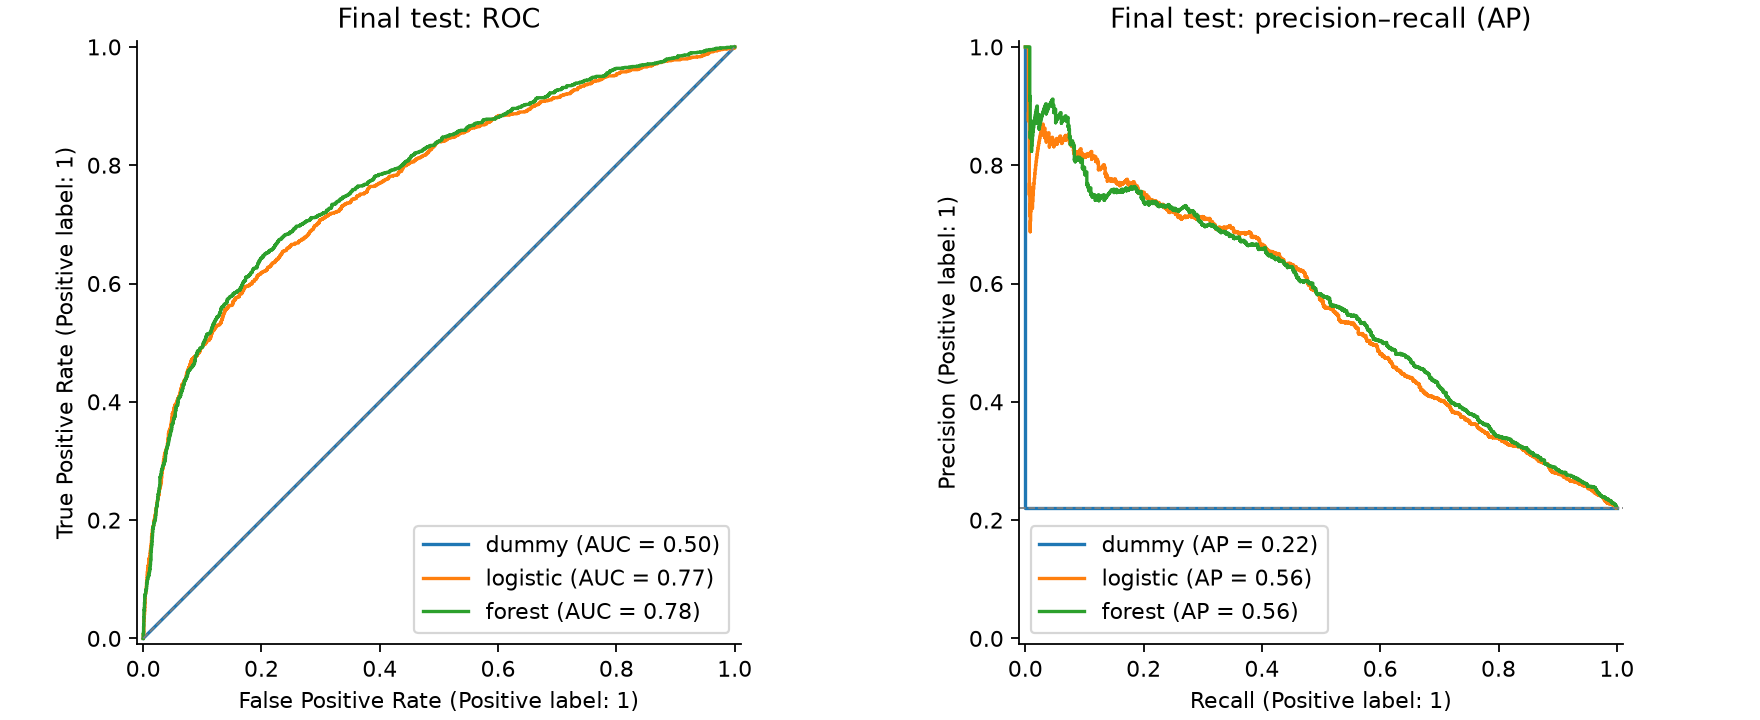

In [3]:
display(pd.read_csv(RUN / 'test_metrics.csv'))
display(Image(filename=str(RUN / 'figures/roc_pr.png')))

## Threshold and errors
The validation budget is 20%; the frozen threshold flags 20.93% of test customers.
This is not a hard future quota. Confusion matrices use actual labels on rows and
predicted labels on columns. False positives are flagged non-defaults, not proven
financial losses; false negatives are missed defaults, not avoidable losses.

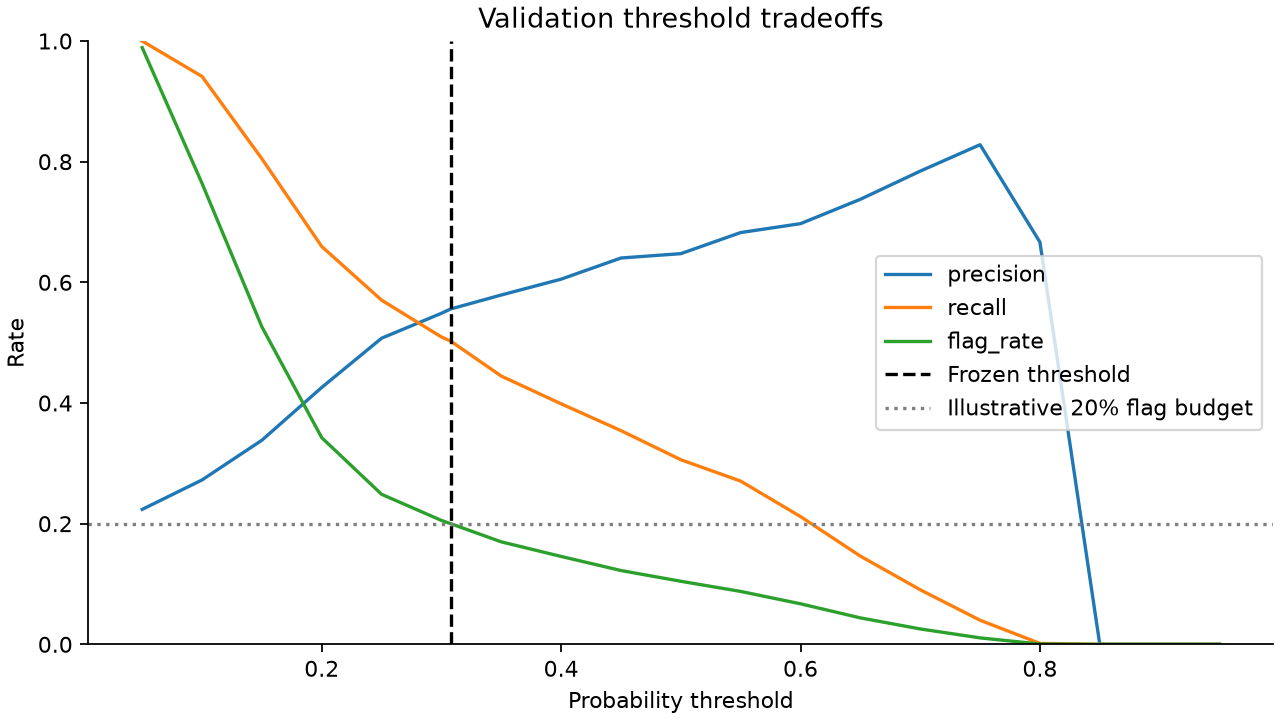

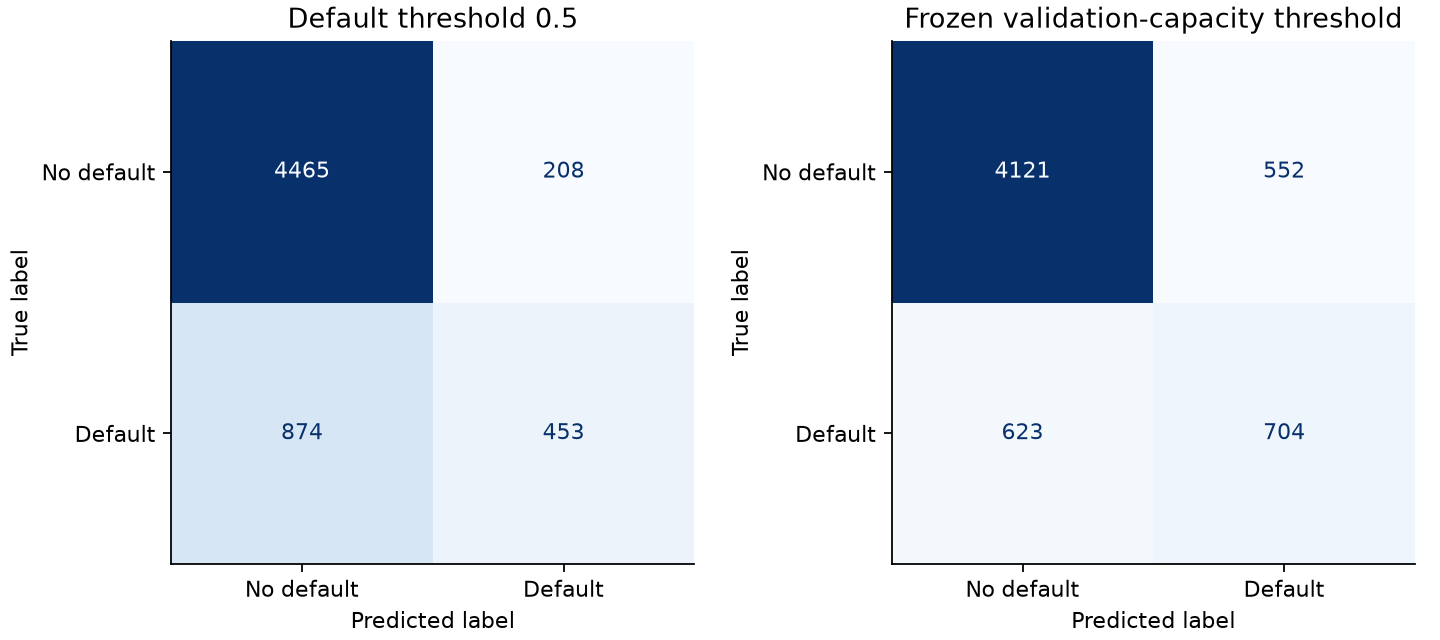

In [4]:
display(Image(filename=str(RUN / 'figures/threshold_tradeoffs.png')))
display(Image(filename=str(RUN / 'figures/confusion_matrices.png')))

## Calibration and interpretation
Brier score is not a pure calibration statistic. Reliability bins are descriptive
and noisy. The coefficient plot uses full regularized one-hot encoding, not a
dropped reference category. Permutation importance uses validation only and does
not establish causality.

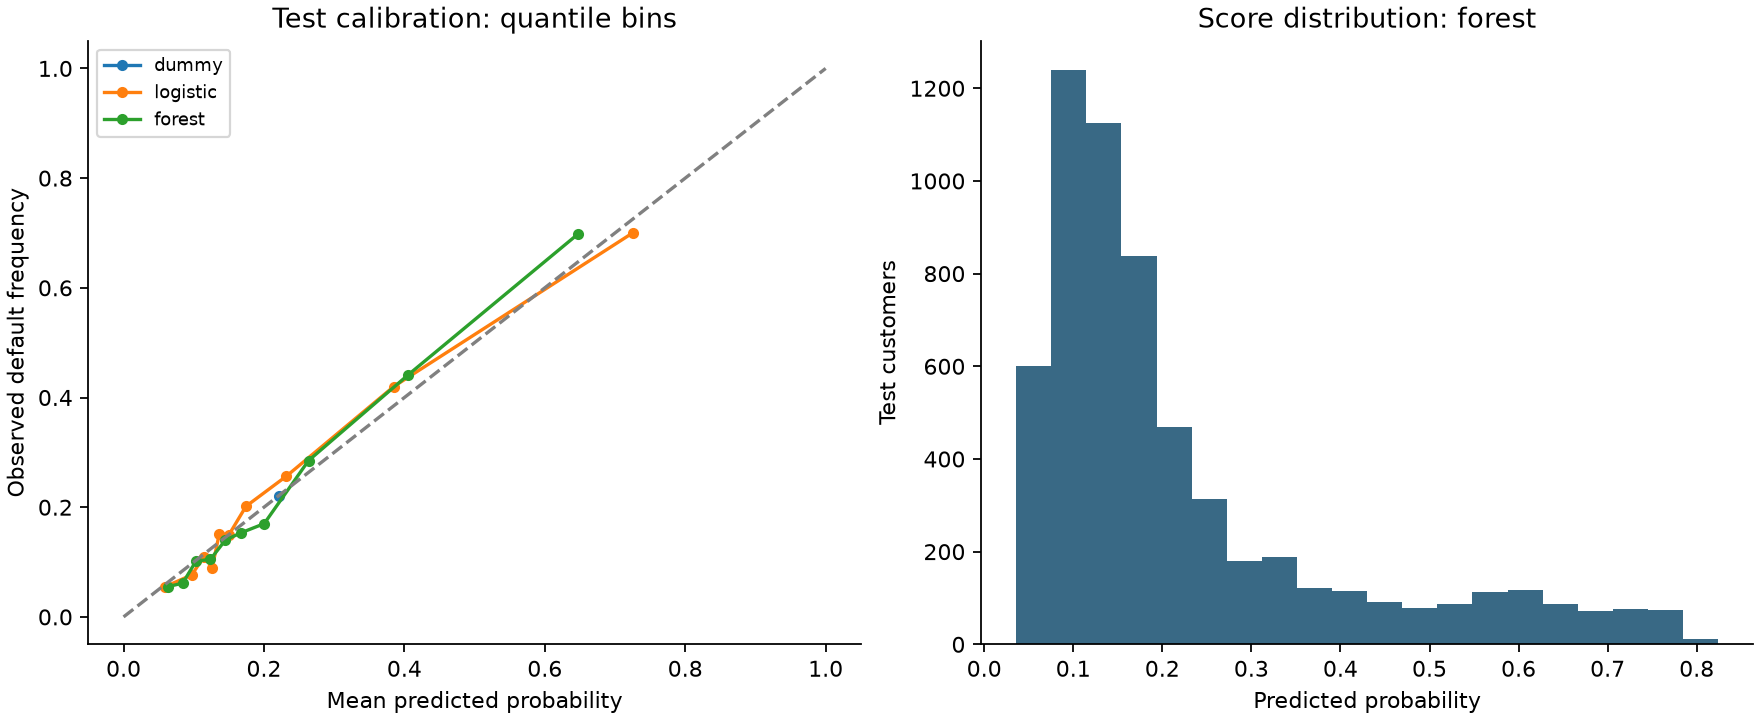

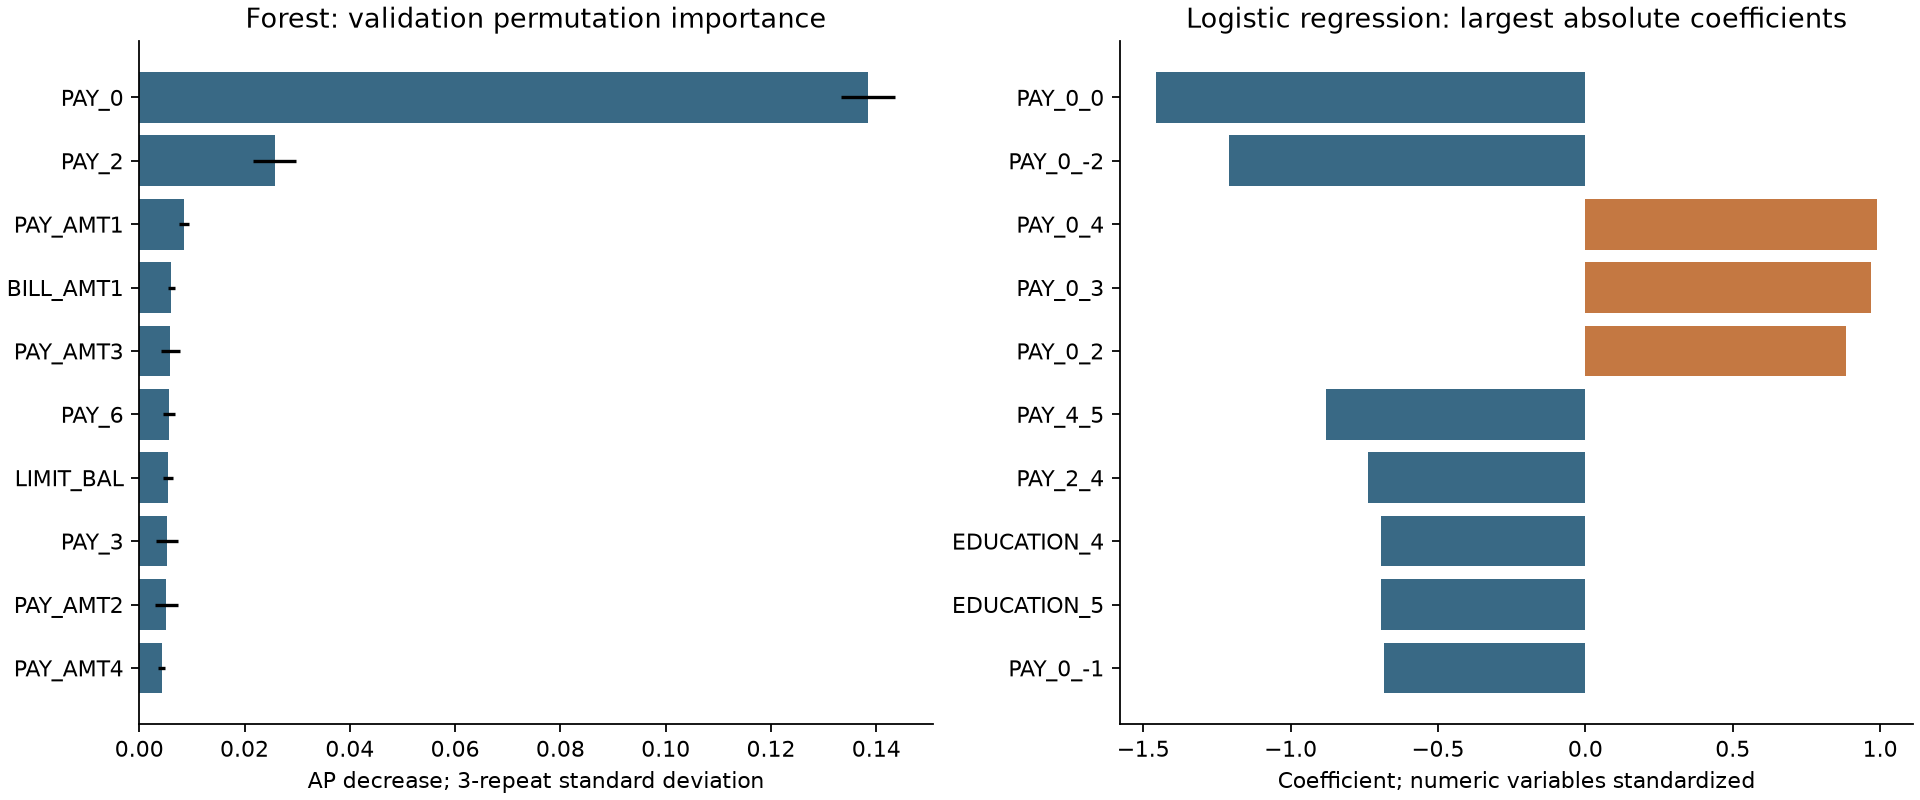

In [5]:
display(Image(filename=str(RUN / 'figures/calibration.png')))
display(Image(filename=str(RUN / 'figures/feature_interpretation.png')))

## Subgroup diagnostic and sampling uncertainty
Same threshold for all groups; rate denominators under 20 are suppressed. These
limited group comparisons do not establish fairness or compliance. Bootstrap
intervals condition on this frozen model/sample and omit selection and shift uncertainty.

In [6]:
display(pd.read_csv(RUN / 'test_subgroups.csv'))
display(json.loads((RUN / 'bootstrap_intervals.json').read_text()))

,attribute,group,n,positives,negatives,flagged,prevalence,flag_rate,recall,fpr,precision,tn,fp,fn,tp
0,sex_source_code,female (source code 2),3628,755,2873,721,0.208104,0.198732,0.535099,0.110338,0.560333,2556,317,351,404
1,sex_source_code,male (source code 1),2372,572,1800,535,0.241147,0.225548,0.524476,0.130556,0.560748,1565,235,272,300
2,age_band,30 to 49,3502,757,2745,672,0.216162,0.191890,0.504624,0.105647,0.568452,2455,290,375,382
3,age_band,50 and older,572,149,423,136,0.260490,0.237762,0.516779,0.139480,0.566176,364,59,72,77
4,age_band,under 30,1926,421,1505,448,0.218588,0.232606,0.581948,0.134884,0.546875,1302,203,176,245


{'replicates': 200,
 'roc_auc_95_percentile': [0.7690790290766352, 0.7968020663066419],
 'ap_95_percentile': [0.5359419451712569, 0.5889086902139642],
 'scope': 'Conditional on the frozen model and this sample; excludes selection and population-shift uncertainty.'}

## Limits to explain
Historical Taiwan snapshot; no temporal backtest; existing-customer selection;
ambiguous outcome/code definitions; 59 repeated predictor-profile groups span
partitions under distinct IDs; uncertain operational costs and intervention effects.
No post-test changes or fabricated business benefits. See `reports/model_results.md`
for the complete explanation and `docs/interview_guide.md` for preparation.